# 0 Setup

In [1]:
!pip install anthropic

import re
import warnings
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from nltk.corpus import words
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud, STOPWORDS
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

nltk.download(["vader_lexicon", "words"])

from dotenv import load_dotenv
load_dotenv()

warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)



[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\home\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package words to
[nltk_data]     C:\Users\home\AppData\Roaming\nltk_data...
[nltk_data]   Package words is already up-to-date!


In [2]:
df = pd.read_csv('youtube_comments.csv', encoding='utf-8')

In [3]:
df.head(5)

,video_id,video_title,comment
0,TcMBFSGVi1c,Avengers Endgame Trailer,Furei a boca com espinho de peixe
1,TcMBFSGVi1c,Avengers Endgame Trailer,Sou budista Jesus Cristo
2,TcMBFSGVi1c,Avengers Endgame Trailer,Is there any chance of iron man returning back...
3,TcMBFSGVi1c,Avengers Endgame Trailer,TOMORROW. DOOM COMES FOR US ALL.
4,TcMBFSGVi1c,Avengers Endgame Trailer,saw this movie again today


In [4]:
import pandas as pd
from langdetect import detect, DetectorFactory

# Make language detection deterministic across runs
DetectorFactory.seed = 42

# 1. Drop empty comments first
df = df.dropna(subset=['comment', 'video_title']).copy()

# 2. Filter for Avengers videos (case-insensitive)
avengers_df = df[df['video_title'].str.contains('avengers', case=False, na=False)].copy()

# 3. Helper function to safely detect English text
def is_english(text):
    try:
        return detect(str(text)) == 'en'
    except:
        return False

# 4. Keep only English comments
avengers_en_df = avengers_df[avengers_df['comment'].apply(is_english)].copy()

print(f"Total rows: {len(df)}")
print(f"Avengers rows: {len(avengers_df)}")
print(f"Avengers + English rows: {len(avengers_en_df)}")

# Safely save filtered file (skips overwriting if locked in Excel)
try:
    avengers_en_df.to_csv('Avengers_Movie_trailer_review.csv', index=False, encoding='utf-8-sig')
    print("Saved Avengers_Movie_trailer_review.csv successfully.")
except PermissionError:
    print("Warning: Close 'Avengers_Movie_trailer_review.csv' in Excel to overwrite it. Continuing in memory...")

Total rows: 66802
Avengers rows: 8409
Avengers + English rows: 5294
Saved Avengers_Movie_trailer_review.csv successfully.


In [5]:
avengers_en_df.head(5)

,video_id,video_title,comment
1,TcMBFSGVi1c,Avengers Endgame Trailer,Sou budista Jesus Cristo
2,TcMBFSGVi1c,Avengers Endgame Trailer,Is there any chance of iron man returning back...
4,TcMBFSGVi1c,Avengers Endgame Trailer,saw this movie again today
5,TcMBFSGVi1c,Avengers Endgame Trailer,i’m discovering plot elements watching this tr...
7,TcMBFSGVi1c,Avengers Endgame Trailer,I was too young to have known about avengers w...


# Open the newly saved file

In [6]:
Avengers_trailer = pd.read_csv('Avengers_Movie_trailer_review.csv')

# Exploratory Data Analysis

In [7]:
Avengers_trailer.head(5)

,video_id,video_title,comment
0,TcMBFSGVi1c,Avengers Endgame Trailer,Sou budista Jesus Cristo
1,TcMBFSGVi1c,Avengers Endgame Trailer,Is there any chance of iron man returning back...
2,TcMBFSGVi1c,Avengers Endgame Trailer,saw this movie again today
3,TcMBFSGVi1c,Avengers Endgame Trailer,i’m discovering plot elements watching this tr...
4,TcMBFSGVi1c,Avengers Endgame Trailer,I was too young to have known about avengers w...


In [8]:
Avengers_trailer = Avengers_trailer.drop(0)

In [9]:
Avengers_trailer.head(5)

,video_id,video_title,comment
1,TcMBFSGVi1c,Avengers Endgame Trailer,Is there any chance of iron man returning back...
2,TcMBFSGVi1c,Avengers Endgame Trailer,saw this movie again today
3,TcMBFSGVi1c,Avengers Endgame Trailer,i’m discovering plot elements watching this tr...
4,TcMBFSGVi1c,Avengers Endgame Trailer,I was too young to have known about avengers w...
5,TcMBFSGVi1c,Avengers Endgame Trailer,Endgame coming back to cinemas for doomsday I ...


In [10]:
Avengers_trailer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5293 entries, 1 to 5293
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   video_id     5293 non-null   object
 1   video_title  5293 non-null   object
 2   comment      5293 non-null   object
dtypes: object(3)
memory usage: 124.2+ KB


In [11]:
Avengers_trailer.describe()

,video_id,video_title,comment
count,5293,5293,5293
unique,11,1,5293
top,KCSNFZKbhZE,Avengers Endgame Trailer,Is there any chance of iron man returning back...
freq,788,5293,1


In [12]:
Avengers_trailer.shape

(5293, 3)

In [13]:
def clean_Avengers_trailer(comment):
    comment = re.sub(r"http\S+|www\.\S+", " ", comment)   # URLs
    comment = re.sub(r"@\w+", " ", comment)               # @mentions
    comment = comment.replace("&amp;", "&").replace("#", "")
    return re.sub(r"\s+", " ", comment).strip()

Avengers_trailer['clean'] = Avengers_trailer["comment"].apply(clean_Avengers_trailer)
Avengers_trailer[['comment', 'clean']].sample(5)

,comment,clean
2461,Only thing I don't like about this is Thor and...,Only thing I don't like about this is Thor and...
2733,BIGGEST REGRET IN MY LIFE FOR NOT SEEING THIS ...,BIGGEST REGRET IN MY LIFE FOR NOT SEEING THIS ...
767,Doomsday trailer in the Super Bowl is going to...,Doomsday trailer in the Super Bowl is going to...
3238,Can't believe this has been 2 years,Can't believe this has been 2 years
4874,Am I just blind or did they not include captai...,Am I just blind or did they not include captai...


In [14]:
Avengers_trailer.head(5)

,video_id,video_title,comment,clean
1,TcMBFSGVi1c,Avengers Endgame Trailer,Is there any chance of iron man returning back...,Is there any chance of iron man returning back...
2,TcMBFSGVi1c,Avengers Endgame Trailer,saw this movie again today,saw this movie again today
3,TcMBFSGVi1c,Avengers Endgame Trailer,i’m discovering plot elements watching this tr...,i’m discovering plot elements watching this tr...
4,TcMBFSGVi1c,Avengers Endgame Trailer,I was too young to have known about avengers w...,I was too young to have known about avengers w...
5,TcMBFSGVi1c,Avengers Endgame Trailer,Endgame coming back to cinemas for doomsday I ...,Endgame coming back to cinemas for doomsday I ...


In [15]:
english_vocab = set(w.lower() for w in words.words())
marvel_slang = {
    "avengers", "endgame", "thanos", "ironman", "spidey", "spiderman",
    "thor", "loki", "hulk", "hawkeye", "natasha", "wandavision", "mcu",
    "trailer", "teasers", "teaser", "doomsday", "ultron", "wakanda",
    "multiverse", "snap", "rewatch", "youtube", "omg", "lol", "bro",
    "bruh", "idk", "ngl", "imo", "tbh", "wtf", "gonna", "wanna", "gotta",
    "rdj", "cap", "stark", "rogers", "romanoff", "barton", "banner",
    "strange", "gamora", "nebula", "groot", "rocket", "drax", "mantis",
    "vision", "wanda", "brie", "larson", "holland", "evans", "hemsworth",
    "ruffalo", "johansson", "renner", "brolin", "russo", "feige", "stan"
}
valid_words = english_vocab.union(marvel_slang)

def is_clean_english(text, min_ratio=0.70):
    tokens = re.findall(r"[a-zA-Z]+", str(text).lower())
    if not tokens:
        return False
    known_count = sum(1 for t in tokens if t in valid_words)
    return (known_count / len(tokens)) >= min_ratio

# Filter Avengers_trailer to keep only clean English rows
keep_mask = Avengers_trailer["clean"].apply(is_clean_english)
Avengers_trailer = Avengers_trailer[keep_mask].reset_index(drop=True)

print(f"Remaining clean English rows: {len(Avengers_trailer)}")
Avengers_trailer.head(5)

Remaining clean English rows: 4848


,video_id,video_title,comment,clean
0,TcMBFSGVi1c,Avengers Endgame Trailer,Is there any chance of iron man returning back...,Is there any chance of iron man returning back...
1,TcMBFSGVi1c,Avengers Endgame Trailer,saw this movie again today,saw this movie again today
2,TcMBFSGVi1c,Avengers Endgame Trailer,i’m discovering plot elements watching this tr...,i’m discovering plot elements watching this tr...
3,TcMBFSGVi1c,Avengers Endgame Trailer,I was too young to have known about avengers w...,I was too young to have known about avengers w...
4,TcMBFSGVi1c,Avengers Endgame Trailer,Endgame coming back to cinemas for doomsday I ...,Endgame coming back to cinemas for doomsday I ...


# Word Cloud

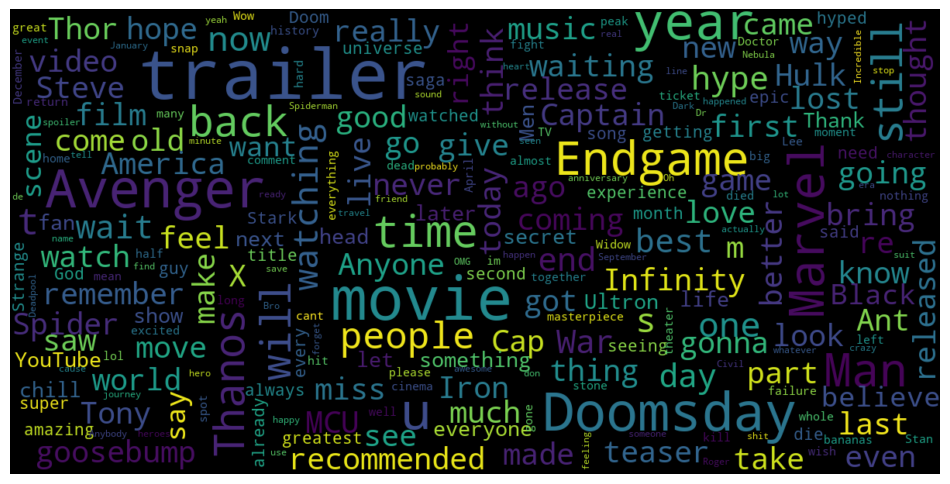

In [16]:
Avengers = Avengers_trailer['clean'].str.cat(sep=" ")

all_stopwords = STOPWORDS

wordcloud = WordCloud(
    background_color = 'black',
    stopwords = all_stopwords,
    max_words = 300,
    max_font_size = 30,
    scale = 3,
    random_state = 1,
    collocations = False
).generate(Avengers)

plt.figure(figsize=(12, 12))
plt.imshow(wordcloud, interpolation = 'bilinear')
plt.axis('off')
plt.show()

In [17]:
Avengers_trailer.columns

Index(['video_id', 'video_title', 'comment', 'clean'], dtype='object')

# Create a Manually Labeled Sample Subset 

#### The data set I got doesn't have a Sentiment label that is needed for the train and test split.

In [18]:
#sample for 500 reviews to label manually

sample_df = Avengers_trailer[['clean']].sample(n=500, random_state=42).copy()
sample_df['human_label'] = ""  #I will manually fill this in Excel with positive, negative or neutral
sample_df.to_csv('manual_validation_sample.csv', index=False)

In [19]:
sample_df.head(10)

,clean,human_label
3879,Too much fun,
1684,It’s a tradition to come here once in a while.,
1044,"Nahh, there is no way this was 7 years ago. Fe...",
4808,The thing is Spider-Man dissapeared but there ...,
1538,"After even 6 years, it gives goosbumps. The ep...",
1034,Wish we could go back- no pandemic and Trump w...,
2107,"June 2025 ,anyone 😭😭😭",
4259,I wish Peggy will come back,
4023,I CANT FUCKING WAIT OMG,
4154,Stan lee never saw this....,


In [20]:
human_labelled = pd.read_csv('manually_validated_sample - with human labels.csv')
human_labelled['human_label'] = human_labelled['human_label'].str.strip().str.lower()
print(human_labelled['human_label'].value_counts(dropna=False))

human_label
neutral     269
positive    187
negative     44
Name: count, dtype: int64


In [21]:
human_labelled.head(10)

,clean,human_label
0,Too much fun,positive
1,It’s a tradition to come here once in a while.,positive
2,"Nahh, there is no way this was 7 years ago. Fe...",neutral
3,The thing is Spider-Man dissapeared but there ...,neutral
4,"After even 6 years, it gives goosbumps. The ep...",positive
5,Wish we could go back- no pandemic and Trump w...,positive
6,"June 2025 ,anyone 😭😭😭",neutral
7,I wish Peggy will come back,neutral
8,I CANT FUCKING WAIT OMG,positive
9,Stan lee never saw this....,negative


In [22]:
# 1. Class Balance (counts and percentages)
print("=== Class Balance ===")
counts = human_labelled['human_label'].value_counts()
percentages = human_labelled['human_label'].value_counts(normalize=True) * 100
class_summary = pd.DataFrame({'Count': counts, 'Percentage (%)': percentages.round(2)})
print(class_summary)
print()

# 2. Average Text Length (in characters and words)
human_labelled['char_length'] = human_labelled['clean'].astype(str).str.len()
human_labelled['word_length'] = human_labelled['clean'].astype(str).str.split().str.len()

print("=== Average Text Length (Overall) ===")
print(f"Average Characters: {human_labelled['char_length'].mean():.2f}")
print(f"Average Words:      {human_labelled['word_length'].mean():.2f}")
print()

print("=== Average Text Length by Class ===")
print(human_labelled.groupby('human_label')[['char_length', 'word_length']].mean().round(2))
print()

# 3. Print 10 Random Examples per Class
print("=== 10 Random Examples per Class ===")
for sentiment in ['positive', 'neutral', 'negative']:
    print(f"\n--- {sentiment.upper()} ---")
    subset = human_labelled[human_labelled['human_label'] == sentiment]
    samples = subset['clean'].sample(n=min(10, len(subset)), random_state=42)
    for i, text in enumerate(samples, 1):
        print(f"{i}. {text}")

=== Class Balance ===
             Count  Percentage (%)
human_label                       
neutral        269            53.8
positive       187            37.4
negative        44             8.8

=== Average Text Length (Overall) ===
Average Characters: 74.99
Average Words:      14.07

=== Average Text Length by Class ===
             char_length  word_length
human_label                          
negative          100.95        18.45
neutral            67.17        12.73
positive           80.13        14.96

=== 10 Random Examples per Class ===

--- POSITIVE ---
1. I still remember watching this live, at the time there was no other trailer besides the awful teaser trailer. This trailer really set the stakes, showing that our heroes are in for the fight of their life and if they loose...Then the universe's last hope will be lost. This will be the fight of their lives and they will do anything in their power to return peace to the universe.
2. I watch this once a week
3. Who's here af

# Auto Label using Vader, then train and evaluate

### Generate sentiment labels - positive, neutral, negative

In [23]:
sia = SentimentIntensityAnalyzer()

# Neutralize Marvel-specific title words and common misspellings
for word in ["doom", "doomsday", "dooms", "doomsay", "doomed"]:
    sia.lexicon[word] = 0.0

def get_sentiment(text):
    score = sia.polarity_scores(str(text))["compound"]
    if score >= 0.05:
        return "positive"
    elif score <= -0.05:
        return "negative"
    else:
        return "neutral"

Avengers_trailer["sentiment"] = Avengers_trailer["clean"].apply(get_sentiment)
print(Avengers_trailer["sentiment"].value_counts())

sentiment
positive    1944
neutral     1795
negative    1109
Name: count, dtype: int64


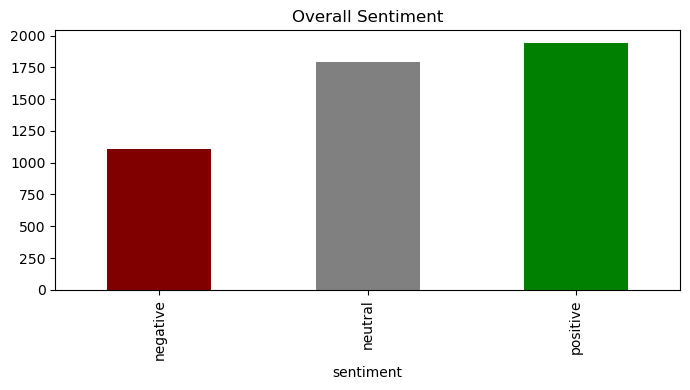

In [24]:
fig, ax = plt.subplots(figsize=(7,4))

Avengers_trailer['sentiment'].value_counts().reindex(['negative', 'neutral', 'positive']).plot.bar(
    ax=ax, color=['maroon', 'gray','green'])
ax.set_title("Overall Sentiment")

plt.tight_layout()
plt.show()


# Train & Test Split

In [25]:
# 1. Remove the 500 human-labeled validation rows from the main dataset before splitting
remaining_df = Avengers_trailer.drop(index=sample_df.index)

train, test = train_test_split(
    remaining_df,
    test_size=0.2,
    random_state=42,
    stratify=remaining_df["sentiment"]
)

y_train = train['sentiment'].to_numpy()
y_test = test['sentiment'].to_numpy()

print(f"Train data = {len(train)}; Test data = {len(test)}")

# 2. Update evaluate() to benchmark against your 500 human labels
y_human = human_labelled['human_label'].to_numpy()
preds = {}
results = {}
labels = ["negative", "neutral", "positive"]

Train data = 3478; Test data = 870


# Model 1 VADER - lexicon + rules, built for social media

### VADER Examples

In [26]:
vader = sia

examples = [
    "Is there any chance of iron man returning back in present 🤕",
    "saw this movie again today",
    "i’m discovering plot elements watching this trailer years later 😓",
    "I was too young to have known about avengers when this masterpiece came out. I've regretted not being able to watch not even one of the movies of this epic franchise in the theatres...when it came out...with the whole fandom🔥😭🥺 I can only hope doomsday would fill that gap for me😭♥️😔",
    "Endgame coming back to cinemas for doomsday I am excited for it",
    "We will return in Avengers Doomsday ❤️‍🩹",
    "You just had to be there man, new gen will never understand",
    "A month from now, it would've been 7 years since it was released.",
    "I like this one",
    ",,Whatever it takes- Doom will quote them surely",
]


In [27]:
pd.DataFrame(
    [{"text": s, **vader.polarity_scores(s)} for s in examples]
).round(3)

,text,neg,neu,pos,compound
0,Is there any chance of iron man returning back...,0.000,0.867,0.133,0.250
1,saw this movie again today,0.000,1.000,0.000,0.000
2,i’m discovering plot elements watching this tr...,0.189,0.811,0.000,-0.422
3,I was too young to have known about avengers w...,0.139,0.696,0.165,0.472
4,Endgame coming back to cinemas for doomsday I ...,0.000,0.821,0.179,0.340
5,We will return in Avengers Doomsday ❤️‍🩹,0.000,1.000,0.000,0.000
6,"You just had to be there man, new gen will nev...",0.000,1.000,0.000,0.000
7,"A month from now, it would've been 7 years sin...",0.000,1.000,0.000,0.000
8,I like this one,0.000,0.545,0.455,0.361
9,",,Whatever it takes- Doom will quote them surely",0.000,0.707,0.293,0.440


In [28]:
def vader_label(text, threshold=0.05):
    c = vader.polarity_scores(text)['compound']

    if c >= threshold:
        return "positive"
    elif c<= -threshold:
        return "negative"
    else: 
        return "neutral"

## Main Model

In [29]:
def evaluate(name, y_pred):
    y_pred = np.asarray(y_pred)
    preds[name] = y_pred

    results[name] = {
        "accuracy": accuracy_score(y_human, y_pred),
        "macro_f1": f1_score(y_human, y_pred, labels=labels, average="macro")
    }

    print(f"==={name} (Human Validation n={len(y_human)})===")
    print(classification_report(y_human, y_pred, labels=labels, digits=3, zero_division=0))

# 3. Evaluate Model 1 (VADER) on human_labelled
evaluate("VADER", human_labelled['clean'].apply(vader_label))

===VADER (Human Validation n=500)===
              precision    recall  f1-score   support

    negative      0.239     0.591     0.340        44
     neutral      0.630     0.431     0.512       269
    positive      0.478     0.529     0.503       187

    accuracy                          0.482       500
   macro avg      0.449     0.517     0.452       500
weighted avg      0.539     0.482     0.493       500



In [30]:
results

{'VADER': {'accuracy': 0.482, 'macro_f1': 0.45151621082164745}}

# Model 2: TextBlob - General Purpose Lexicon

#### sentiment - polarity;  subjectivity

In [31]:
examples = [
    "Is there any chance of iron man returning back in present 🤕",
    "saw this movie again today",
    "i’m discovering plot elements watching this trailer years later 😓",
    "I was too young to have known about avengers when this masterpiece came out. I've regretted not being able to watch not even one of the movies of this epic franchise in the theatres...when it came out...with the whole fandom🔥😭🥺 I can only hope doomsday would fill that gap for me😭♥️😔",
    "Endgame coming back to cinemas for doomsday I am excited for it",
    "We will return in Avengers Doomsday ❤️‍🩹",
    "You just had to be there man, new gen will never understand",
    "A month from now, it would've been 7 years since it was released.",
    "I like this one",
    ",,Whatever it takes- Doom will quote them surely",
]

In [32]:
pd.DataFrame(
    [{
        "text": s,
        "polarity": TextBlob(s).sentiment.polarity,
        "subjectivity": TextBlob(s).sentiment.subjectivity}
        for s in examples]
)

,text,polarity,subjectivity
0,Is there any chance of iron man returning back...,0.000000,0.000000
1,saw this movie again today,0.000000,0.000000
2,i’m discovering plot elements watching this tr...,0.000000,0.000000
3,I was too young to have known about avengers w...,0.180000,0.565000
4,Endgame coming back to cinemas for doomsday I ...,0.187500,0.375000
5,We will return in Avengers Doomsday ❤️‍🩹,0.000000,0.000000
6,"You just had to be there man, new gen will nev...",0.136364,0.454545
7,"A month from now, it would've been 7 years sin...",0.000000,0.000000
8,I like this one,0.000000,0.000000
9,",,Whatever it takes- Doom will quote them surely",0.500000,0.888889


## Main Model

In [33]:
def textblob_label(text, threshold=0.2):
    p = TextBlob(text).sentiment.polarity
    if p >= threshold:
        return "positive"
    elif p <= -threshold:
        return "negative"
    else:
        return "neutral"

In [34]:
evaluate("TextBlob", human_labelled['clean'].apply(textblob_label))

===TextBlob (Human Validation n=500)===
              precision    recall  f1-score   support

    negative      0.364     0.273     0.312        44
     neutral      0.618     0.788     0.693       269
    positive      0.565     0.374     0.450       187

    accuracy                          0.588       500
   macro avg      0.515     0.478     0.485       500
weighted avg      0.576     0.588     0.569       500



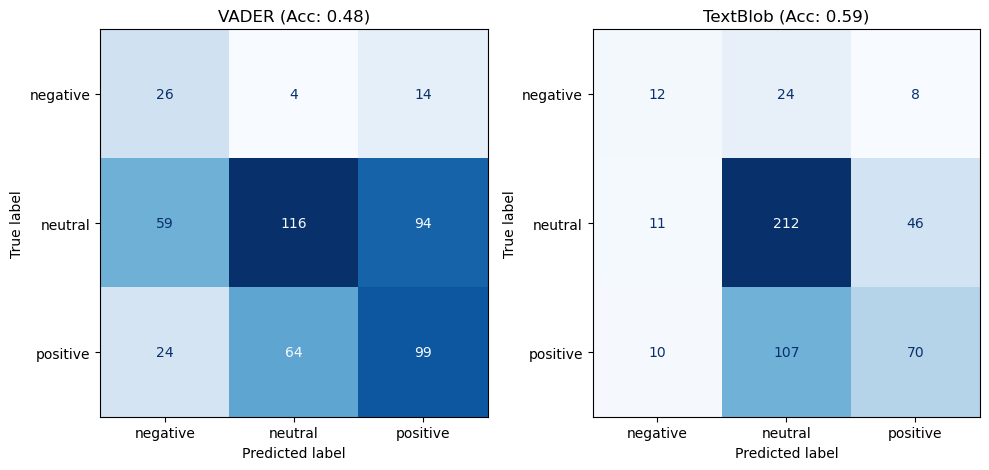

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6))

for ax, name in zip(axes, ["VADER", "TextBlob"]):
    cm = confusion_matrix(y_human, preds[name], labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} (Acc: {results[name]['accuracy']:.2f})")

plt.tight_layout()
plt.show()

In [36]:
side_by_side_preds = pd.DataFrame({
    "Comment": human_labelled["clean"],
    "Human Label": y_human,
    "VADER": preds["VADER"],
    "TextBlob": preds["TextBlob"]
})

# Show the first 15 rows 
side_by_side_preds.head(15)
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(side_by_side_preds.head(15))

,Comment,Human Label,VADER,TextBlob
0,Too much fun,positive,positive,positive
1,It’s a tradition to come here once in a while.,positive,neutral,neutral
2,"Nahh, there is no way this was 7 years ago. Felt like it's only been 3 years",neutral,positive,neutral
3,The thing is Spider-Man dissapeared but there is a Spider-Man movie coming out,neutral,neutral,neutral
4,"After even 6 years, it gives goosbumps. The epic time of MCU saga!",positive,neutral,neutral
5,Wish we could go back- no pandemic and Trump was on his way out.,positive,positive,neutral
6,"June 2025 ,anyone 😭😭😭",neutral,negative,neutral
7,I wish Peggy will come back,neutral,positive,neutral
8,I CANT FUCKING WAIT OMG,positive,neutral,negative
9,Stan lee never saw this....,negative,neutral,neutral


# Model 3: NLTK + Naive Bayes

In [37]:
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords
from nltk.sentiment.util import mark_negation
from nltk import NaiveBayesClassifier, FreqDist
nltk.download("stopwords")


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\home\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [38]:
tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True, strip_handles=True)

KEEP = {"no", "nor", "not", "very", "too", "against"}
STOP = {w for w in stopwords.words("english") if w not in KEEP and "n't" not in w}

In [39]:
def Avengers_tokens(text):
    tokens = tokenizer.tokenize(str(text))
    tokens = mark_negation(tokens)
    return [t for t in tokens 
        if t.replace("_NEG", "") not in STOP and re.search(r"\w", t)]

In [40]:
print(Avengers_tokens("I do NOT like this movie, the delay was too long"))

['not', 'like_NEG', 'movie_NEG', ',_NEG', 'delay_NEG', 'too_NEG', 'long_NEG']


## Main Model

In [41]:
train_tokens = [Avengers_tokens(t) for t in train['clean']]
test_tokens = [Avengers_tokens(t) for t in  test['clean']]

In [42]:
freq = FreqDist(w for tokens in train_tokens for w in tokens)
VOCAB = {w for w, _ in freq.most_common(3000)}

In [43]:
def nltk_features(tokens):
    return {w: True for w in set(tokens) if w in VOCAB} # bag-of-words

In [44]:
train_set =[(nltk_features(t), y) for t, y in zip(train_tokens, y_train)]

nb = NaiveBayesClassifier.train(train_set)
nb.show_most_informative_features(50)

Most Informative Features
                    best = True           positi : neutra =     47.0 : 1.0
                  teaser = True           negati : neutra =     44.6 : 1.0
                    good = True           positi : neutra =     43.6 : 1.0
                    like = True           positi : neutra =     43.6 : 1.0
                    miss = True           negati : neutra =     36.0 : 1.0
             recommended = True           positi : neutra =     28.8 : 1.0
                  marvel = True           positi : neutra =     28.1 : 1.0
                    dead = True           negati : positi =     23.7 : 1.0
                    died = True           negati : neutra =     23.1 : 1.0
                    wars = True           negati : neutra =     21.6 : 1.0
                 amazing = True           positi : neutra =     20.1 : 1.0
                    kill = True           negati : positi =     19.1 : 1.0
                    hope = True           positi : neutra =     18.9 : 1.0

In [45]:
# Tokenize the 500 human-labeled validation comments using your custom Avengers_tokens function
human_tokens = [Avengers_tokens(t) for t in human_labelled["clean"]]

evaluate("NLTK + Naive Bayes", [nb.classify(nltk_features(t)) for t in human_tokens])

===NLTK + Naive Bayes (Human Validation n=500)===
              precision    recall  f1-score   support

    negative      0.154     0.614     0.247        44
     neutral      0.733     0.164     0.267       269
    positive      0.506     0.717     0.593       187

    accuracy                          0.410       500
   macro avg      0.464     0.498     0.369       500
weighted avg      0.597     0.410     0.387       500



# Compare all methods

In [46]:
results

{'VADER': {'accuracy': 0.482, 'macro_f1': 0.45151621082164745},
 'TextBlob': {'accuracy': 0.588, 'macro_f1': 0.48488651363627716},
 'NLTK + Naive Bayes': {'accuracy': 0.41, 'macro_f1': 0.36899096669849024}}

In [47]:
summary = pd.DataFrame(results).T.sort_values("macro_f1", ascending=False).round(3)
summary

,accuracy,macro_f1
TextBlob,0.588,0.485
VADER,0.482,0.452
NLTK + Naive Bayes,0.410,0.369


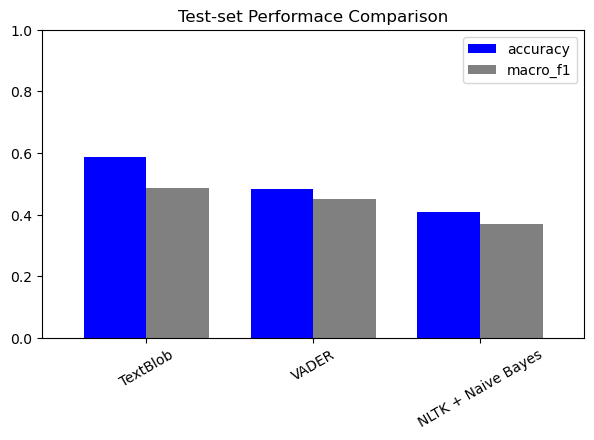

In [48]:
summary.plot.bar(figsize=(7,4), rot=30, width=0.75, color=['blue', 'gray'])
plt.title("Test-set Performace Comparison")
plt.ylim(0,1)
plt.show()

In [49]:
preds.items()

dict_items([('VADER', array(['positive', 'neutral', 'positive', 'neutral', 'neutral',
       'positive', 'negative', 'positive', 'neutral', 'neutral',
       'negative', 'neutral', 'positive', 'positive', 'negative',
       'neutral', 'positive', 'neutral', 'positive', 'positive',
       'neutral', 'negative', 'positive', 'positive', 'positive',
       'neutral', 'negative', 'positive', 'positive', 'negative',
       'positive', 'neutral', 'neutral', 'negative', 'neutral', 'neutral',
       'negative', 'positive', 'positive', 'negative', 'positive',
       'neutral', 'negative', 'neutral', 'positive', 'negative',
       'neutral', 'positive', 'neutral', 'neutral', 'positive', 'neutral',
       'positive', 'negative', 'positive', 'negative', 'neutral',
       'neutral', 'neutral', 'positive', 'positive', 'positive',
       'positive', 'negative', 'negative', 'positive', 'neutral',
       'negative', 'neutral', 'negative', 'positive', 'positive',
       'neutral', 'negative', 'negative',

# Confusion Matrix

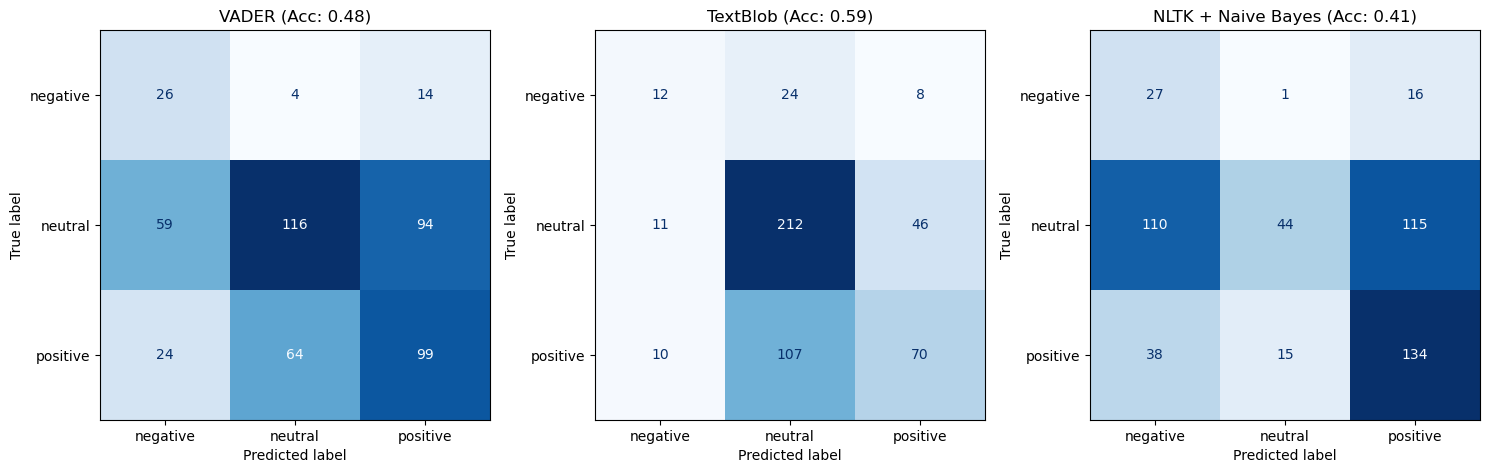

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, name in zip(axes, ["VADER", "TextBlob", "NLTK + Naive Bayes"]):
    cm = confusion_matrix(y_human, preds[name], labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} (Acc: {results[name]['accuracy']:.2f})")

plt.tight_layout()
plt.show()

In [51]:
from sklearn.model_selection import StratifiedKFold

# 1. Evaluate Naive Bayes trained on VADER pseudo-labels
human_tokens = [Avengers_tokens(t) for t in human_labelled["clean"]]
evaluate("NLTK + Naive Bayes (VADER-trained)", [nb.classify(nltk_features(t)) for t in human_tokens])

# 2. Evaluate Naive Bayes trained on actual human labels (5-Fold Cross-Validation)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_human = human_labelled["clean"].to_numpy()
cv_preds = np.empty_like(y_human)

for train_idx, val_idx in skf.split(X_human, y_human):
    fold_train_tokens = [Avengers_tokens(t) for t in X_human[train_idx]]
    fold_freq = FreqDist(w for tokens in fold_train_tokens for w in tokens)
    fold_vocab = {w for w, _ in fold_freq.most_common(1500)}
    
    def get_feats(tokens):
        return {w: True for w in set(tokens) if w in fold_vocab}
    
    fold_train_set = [(get_feats(t), y) for t, y in zip(fold_train_tokens, y_human[train_idx])]
    clf = NaiveBayesClassifier.train(fold_train_set)
    
    for i in val_idx:
        cv_preds[i] = clf.classify(get_feats(Avengers_tokens(X_human[i])))

evaluate("NLTK + Naive Bayes (Human CV)", cv_preds)

===NLTK + Naive Bayes (VADER-trained) (Human Validation n=500)===
              precision    recall  f1-score   support

    negative      0.154     0.614     0.247        44
     neutral      0.733     0.164     0.267       269
    positive      0.506     0.717     0.593       187

    accuracy                          0.410       500
   macro avg      0.464     0.498     0.369       500
weighted avg      0.597     0.410     0.387       500

===NLTK + Naive Bayes (Human CV) (Human Validation n=500)===
              precision    recall  f1-score   support

    negative      0.162     0.727     0.266        44
     neutral      0.797     0.424     0.553       269
    positive      0.613     0.524     0.565       187

    accuracy                          0.488       500
   macro avg      0.524     0.558     0.461       500
weighted avg      0.672     0.488     0.532       500



In [52]:
side_by_side_preds = pd.DataFrame({
    "Comment": human_labelled["clean"],
    "Human Label": y_human,
    "VADER": preds["VADER"],
    "TextBlob": preds["TextBlob"],
    "NB (VADER-trained)": preds["NLTK + Naive Bayes (VADER-trained)"],
    "NB (Human CV)": preds["NLTK + Naive Bayes (Human CV)"]
})

with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(side_by_side_preds.head(15))

,Comment,Human Label,VADER,TextBlob,NB (VADER-trained),NB (Human CV)
0,Too much fun,positive,positive,positive,positive,negative
1,It’s a tradition to come here once in a while.,positive,neutral,neutral,positive,neutral
2,"Nahh, there is no way this was 7 years ago. Felt like it's only been 3 years",neutral,positive,neutral,negative,positive
3,The thing is Spider-Man dissapeared but there is a Spider-Man movie coming out,neutral,neutral,neutral,negative,negative
4,"After even 6 years, it gives goosbumps. The epic time of MCU saga!",positive,neutral,neutral,positive,positive
5,Wish we could go back- no pandemic and Trump was on his way out.,positive,positive,neutral,negative,negative
6,"June 2025 ,anyone 😭😭😭",neutral,negative,neutral,neutral,neutral
7,I wish Peggy will come back,neutral,positive,neutral,positive,positive
8,I CANT FUCKING WAIT OMG,positive,neutral,negative,neutral,positive
9,Stan lee never saw this....,negative,neutral,neutral,negative,negative


,accuracy,macro_f1
TextBlob,0.588,0.485
NLTK + Naive Bayes (Human CV),0.488,0.461
VADER,0.482,0.452
NLTK + Naive Bayes,0.410,0.369
NLTK + Naive Bayes (VADER-trained),0.410,0.369


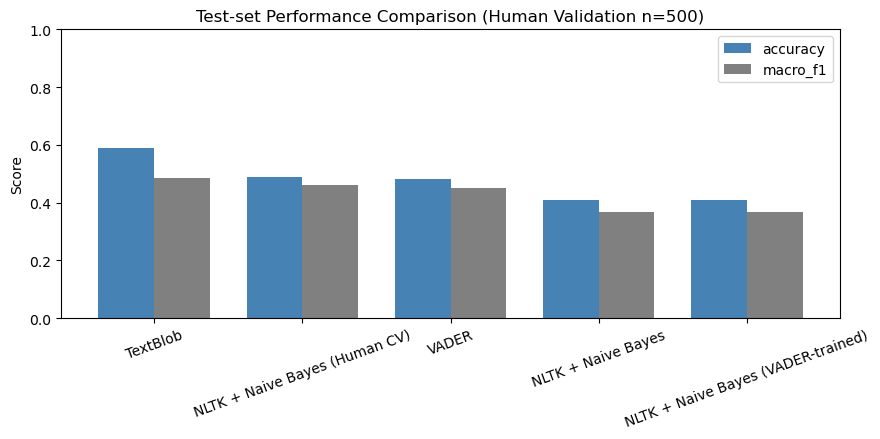

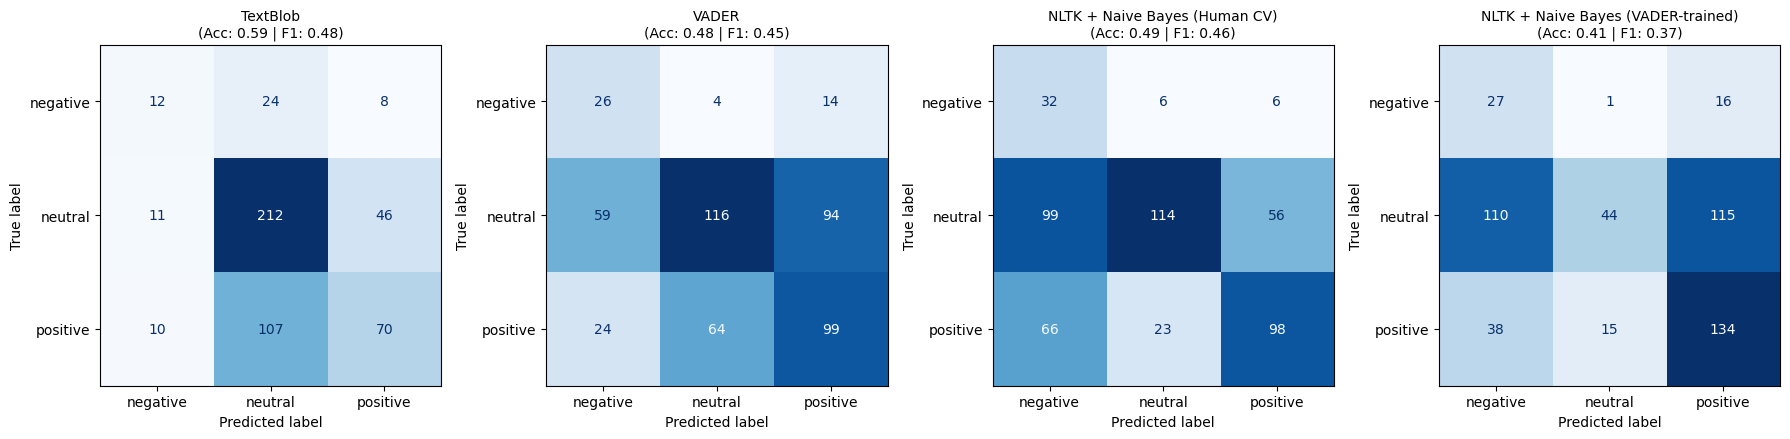

In [53]:
# Summary DataFrame sorted by Macro F1
summary = pd.DataFrame(results).T.sort_values("macro_f1", ascending=False).round(3)
display(summary)

# Bar Chart Comparison
summary.plot.bar(figsize=(9, 4.5), rot=20, width=0.75, color=['steelblue', 'gray'])
plt.title("Test-set Performance Comparison (Human Validation n=500)")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Side-by-Side Confusion Matrices for All Models
model_names = ["TextBlob", "VADER", "NLTK + Naive Bayes (Human CV)", "NLTK + Naive Bayes (VADER-trained)"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for ax, name in zip(axes, model_names):
    cm = confusion_matrix(y_human, preds[name], labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\n(Acc: {results[name]['accuracy']:.2f} | F1: {results[name]['macro_f1']:.2f})", fontsize=10)

plt.tight_layout()
plt.show()

# Error Analysis

In [54]:
errors = human_labelled[['clean', 'human_label']].copy()
errors['VADER'] = preds['VADER']
errors['TextBlob'] = preds['TextBlob']
errors['NLTK + NB (VADER-trained)'] = preds['NLTK + Naive Bayes (VADER-trained)']
errors['NLTK + NB (Human CV)'] = preds['NLTK + Naive Bayes (Human CV)']

# Insert 'Avengers Movie trailer review' as the 1st column (position 0)
errors.insert(0, 'video_title', 'Avengers Movie trailer review')

# Save to CSV (with a fallback if the file is open in Excel)
try:
    errors.to_csv('error_analysis_results.csv', index=False, encoding='utf-8-sig')
    print("Saved 'error_analysis_results.csv' successfully.")
except PermissionError:
    print("Warning: Close 'error_analysis_results.csv' in Excel to overwrite it.")

pd.set_option('display.max_colwidth', 120)
errors.head(15)

Saved 'error_analysis_results.csv' successfully.


,video_title,clean,human_label,VADER,TextBlob,NLTK + NB (VADER-trained),NLTK + NB (Human CV)
0,Avengers Movie trailer review,Too much fun,positive,positive,positive,positive,negative
1,Avengers Movie trailer review,It’s a tradition to come here once in a while.,positive,neutral,neutral,positive,neutral
2,Avengers Movie trailer review,"Nahh, there is no way this was 7 years ago. Felt like it's only been 3 years",neutral,positive,neutral,negative,positive
3,Avengers Movie trailer review,The thing is Spider-Man dissapeared but there is a Spider-Man movie coming out,neutral,neutral,neutral,negative,negative
4,Avengers Movie trailer review,"After even 6 years, it gives goosbumps. The epic time of MCU saga!",positive,neutral,neutral,positive,positive
5,Avengers Movie trailer review,Wish we could go back- no pandemic and Trump was on his way out.,positive,positive,neutral,negative,negative
6,Avengers Movie trailer review,"June 2025 ,anyone 😭😭😭",neutral,negative,neutral,neutral,neutral
7,Avengers Movie trailer review,I wish Peggy will come back,neutral,positive,neutral,positive,positive
8,Avengers Movie trailer review,I CANT FUCKING WAIT OMG,positive,neutral,negative,neutral,positive
9,Avengers Movie trailer review,Stan lee never saw this....,negative,neutral,neutral,negative,negative


In [55]:
def evaluate_timed(name, predict_fn, texts, cost_per_1k=0.0):
    start_time = time.perf_counter()
    y_pred = np.asarray(predict_fn(texts))
    elapsed = time.perf_counter() - start_time
    sec_per_1k = (elapsed / len(texts)) * 1000

    preds[name] = y_pred
    results[name] = {
        "accuracy": accuracy_score(y_human, y_pred),
        "macro_f1": f1_score(y_human, y_pred, labels=labels, average="macro"),
        "sec_per_1k": round(sec_per_1k, 4),
        "cost_per_1k": cost_per_1k
    }

    print(f"=== {name} (n={len(y_human)} | {sec_per_1k:.4f} sec/1k | ${cost_per_1k:.4f}/1k) ===")
    print(classification_report(y_human, y_pred, labels=labels, digits=3, zero_division=0))

# Re-run Tier 1 & Tier 2 models with speed & cost tracking
evaluate_timed("VADER", lambda s: s.apply(vader_label), human_labelled["clean"], cost_per_1k=0.0)
evaluate_timed("TextBlob", lambda s: s.apply(textblob_label), human_labelled["clean"], cost_per_1k=0.0)
evaluate_timed(
    "NLTK + Naive Bayes",
    lambda s: [nb.classify(nltk_features(Avengers_tokens(t))) for t in s],
    human_labelled["clean"],
    cost_per_1k=0.0
)

# Display updated summary table with speed and cost
summary_df = pd.DataFrame(results).T.round(4)
display(summary_df)

=== VADER (n=500 | 0.5227 sec/1k | $0.0000/1k) ===
              precision    recall  f1-score   support

    negative      0.239     0.591     0.340        44
     neutral      0.630     0.431     0.512       269
    positive      0.478     0.529     0.503       187

    accuracy                          0.482       500
   macro avg      0.449     0.517     0.452       500
weighted avg      0.539     0.482     0.493       500

=== TextBlob (n=500 | 1.0667 sec/1k | $0.0000/1k) ===
              precision    recall  f1-score   support

    negative      0.364     0.273     0.312        44
     neutral      0.618     0.788     0.693       269
    positive      0.565     0.374     0.450       187

    accuracy                          0.588       500
   macro avg      0.515     0.478     0.485       500
weighted avg      0.576     0.588     0.569       500

=== NLTK + Naive Bayes (n=500 | 0.5053 sec/1k | $0.0000/1k) ===
              precision    recall  f1-score   support

    negative  

,accuracy,macro_f1,sec_per_1k,cost_per_1k
VADER,0.482,0.4515,0.5227,0.0
TextBlob,0.588,0.4849,1.0667,0.0
NLTK + Naive Bayes,0.410,0.3690,0.5053,0.0
NLTK + Naive Bayes (VADER-trained),0.410,0.3690,NaN,NaN
NLTK + Naive Bayes (Human CV),0.488,0.4613,NaN,NaN


# Model 4: Claude Haiku 5.5

# 0 Setup for Claude Sentiment

In [56]:
!pip install anthropic

In [ ]:
import os, anthropic, httpx2
from dotenv import load_dotenv

load_dotenv(override=True)
key = os.getenv("ANTHROPIC_API_KEY", "").strip()

client = anthropic.Anthropic(
    api_key=key,
    http_client=httpx2.Client(http2=False, verify=False, headers={"Accept-Encoding": "identity"})
)

client = anthropic.Anthropic()
print(repr(client.api_key[:10]), len(client.api_key))


'sk-ant-usr' 106


### I am using human_labelled since my original dataset doesn't contain sentiment column.

In [69]:
human_labelled.head(10) 

,clean,human_label,char_length,word_length
0,Too much fun,positive,12,3
1,It’s a tradition to come here once in a while.,positive,46,10
2,"Nahh, there is no way this was 7 years ago. Felt like it's only been 3 years",neutral,76,17
3,The thing is Spider-Man dissapeared but there is a Spider-Man movie coming out,neutral,78,13
4,"After even 6 years, it gives goosbumps. The epic time of MCU saga!",positive,66,13
5,Wish we could go back- no pandemic and Trump was on his way out.,positive,64,14
6,"June 2025 ,anyone 😭😭😭",neutral,21,4
7,I wish Peggy will come back,neutral,27,6
8,I CANT FUCKING WAIT OMG,positive,23,5
9,Stan lee never saw this....,negative,27,5


In [70]:
human_labelled.shape

(500, 4)

In [71]:
human_labelled.columns

Index(['clean', 'human_label', 'char_length', 'word_length'], dtype='object')

# 2 Claude API (Haiku)

In [72]:
system_prompt = '''You classify the sentiment of reviews written on the Movie Avengers Endgame.
Reply exactly one word: positive, neutral or negative.
Sarcasm counts as its true sentiment (for example "April 2019 ""I love you 3000"" December 2026: ""I hate you 3000""" )'''

In [73]:
def compute_claude_sentiment(text):
    response = client.messages.create(
        model='claude-haiku-5-5',
        max_tokens=10,
        system=system_prompt,
        messages=[{'role': 'user', 'content': f"Avengers Movie trailer review: {text}"}]
    )
    # Grab the first text block, whatever pisition it's in
    answer = next((b.text for b in response.content if b.type == "text"), "").strip().lower()
    return answer if answer in ['positive', 'neutral', 'negative'] else 'neutral'

In [74]:
from dotenv import load_dotenv, find_dotenv
import os, anthropic

env_path = find_dotenv()
print("Loaded .env from:", env_path)

load_dotenv(env_path, override=True)
key = os.getenv("ANTHROPIC_API_KEY", "").strip()
print("Prefix:", repr(key[:13]), "Length:", len(key))

client = anthropic.Anthropic(api_key=key)

Loaded .env from: d:\Documents\Python and AI\Milestone 4\Final\.env
Prefix: 'sk-ant-usr-12' Length: 106


In [ ]:
with open(r"d:\Documents\Python and AI\Milestone 4\Final\.env", "r", encoding="utf-8") as f:
    for i, line in enumerate(f, 1):
        print(f"Line {i}: len={len(line.strip())}, start={repr(line.strip()[:25])}")

Line 1: len=106, start='sk-ant-usr-12_mWd6XorHGbg'


# Applying Claude to Data

In [ ]:
human_labelled['claude_sentiment'] = human_labelled['clean'].apply(compute_claude_sentiment)

df[['clean', 'human_label', 'claude_sentiment']].head()

## Vader Sentiment (Comparison)

In [ ]:
sia = SentimentIntensityAnalyzer

def compute_vader_sentiment(text):
    score = sia.polarity_scores(text)['compound']

    if score >= 0.05:
        return 'positive'
    elif score <= -0.05:
        return 'negative'
    else:
        return 'neutral'

In [ ]:
df['vader_sentiment'] = df['text'].apply(compute_vader_sentiment)

In [ ]:
df

# Comparison of Models

In [ ]:
pd.crosstab(df['sentiment'], df['claude_sentiment'])